# Deel 1 - Les 5 - Boosted Trees en SVM

## **Stap 1:** Libraries

In [1]:
import os
import copy  # to copy variables
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as img # To load the images
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier # The machine learning models
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# Paden relatief t.o.v. deze notebook (map 'Les 5')
DATA_DIR = "flowers"
LABEL_FILE = "all_flower_labels.csv"

## **Stap 2:** Data

### 2.1. Data laden en exploratie
- Laten we beginnen met het laden van een afbeelding van een enkele bloem om de datastructuur te begrijpen. We zullen bekijken hoe afbeeldingen worden opgeslagen en welke informatie ze bevatten
- We gebruiken de functie `imread` van matplotlib om de afbeelding in het geheugen te laden
- Laten we nu de afbeelding weergeven die we zojuist hebben geladen, om te controleren of deze correct is ingelezen

In [2]:
bloem1 = img.imread(os.path.join(DATA_DIR, '0003.png'))

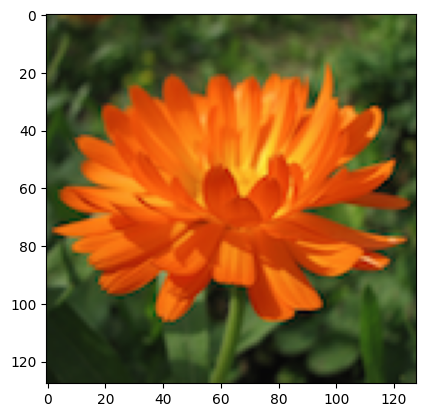

In [3]:
plt.imshow(bloem1)

Laat ons de structuur van de figuur bekijken

In [4]:
bloem1.shape

(128, 128, 4)

De vorm van het data-object is $128$ x $128$ x $4$. De afmetingen van de afbeelding zijn dus 128 bij 128 pixels. De 4 geeft aan dat de data uit 4 lagen bestaat; waarschijnlijk zijn er 3 voor kleur en 1 voor iets anders. Laten we elke laag afzonderlijk plotten om te zien wat we hebben.

Merk op dat indexering in Python bij 0 begint. De eerste laag heeft dus index 0, de tweede laag index 1, enzovoort.

Laten we nu elke kleurlaag afzonderlijk bekijken om te begrijpen welke informatie deze bevat:

layer 1:


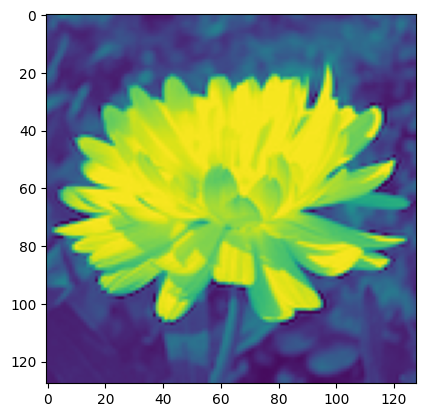

layer 2:


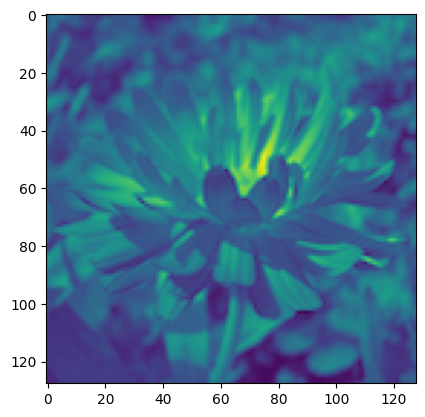

layer 3:


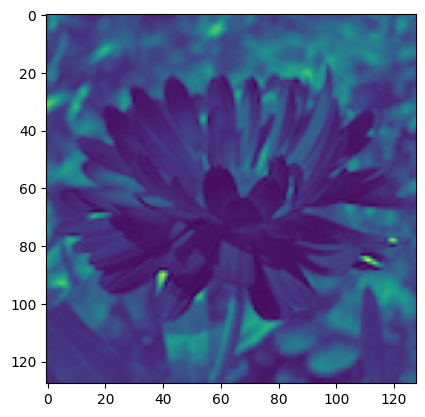

layer 4:


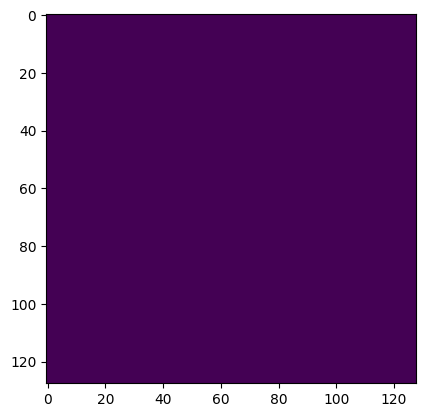

In [5]:
# de vier lagen van de afbeelding apart bekijken
layer1 = bloem1[:,:,0]
layer2 = bloem1[:,:,1]
layer3 = bloem1[:,:,2]
layer4 = bloem1[:,:,3]

for i in range(0,4):
    print(f"layer {i+1}:")
    plt.imshow(bloem1[:,:,i])
    plt.show()

In [6]:
# Wat zit er in laag 4?
print("Unieke waarden in laag 4:", np.unique(layer4))

Unieke waarden in laag 4: [1.]


Oké, er zijn een aantal dingen die we kunnen waarnemen.
- Ten eerste heeft layer4 voor elke pixel dezelfde waarde (1.0). Dit is het **alpha-kanaal** (transparantie) van een PNG-bestand: 1 betekent volledig ondoorzichtig. Het bevat dus geen informatie over de bloem en we hebben het niet nodig.
- Alle lagen lijken te bestaan uit blauw, groen en geel. Hoe zit dat? Dit heeft te maken met de standaardinstelling (colormap `viridis`) van `imshow`, waarbij hoge waarden worden weergegeven in felgeel en lagere waarden in donkerder groen/blauw.
- Hoe kunnen we dit testen? We kunnen de oorspronkelijke afbeelding nemen en bepaalde lagen op nul zetten om te zien wat er gebeurt.

Laten we onze hypothese over RGB-lagen testen door elk kleurkanaal te isoleren. We maken kopieën van de afbeelding en zetten twee lagen op nul, zodat we telkens slechts één kleur zien:

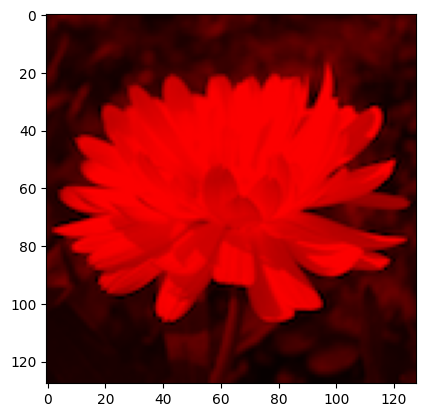

In [7]:
# Laag 1 (Laag 2 en 3 nul)
bloem1_copy = copy.deepcopy(bloem1)
bloem1_copy[:,:,1] = np.zeros_like(layer2) # zet laag 2 allemaal op nul
bloem1_copy[:,:,2] = np.zeros_like(layer3) # zet laag 3 allemaal op nul
plt.imshow(bloem1_copy)

Oké, nu komen we ergens. We zetten laag 2 en 3 (index 1 en 2, weet je nog) op nul en de uiteindelijke afbeelding is volledig rood. We kunnen concluderen dat laag 1 de rode kleur bevat. Laten we er dus voorlopig van uitgaan dat de eerste laag inderdaad rood is en de volgende lagen groen en blauw (RGB). Laten we de andere lagen ook eens bekijken!

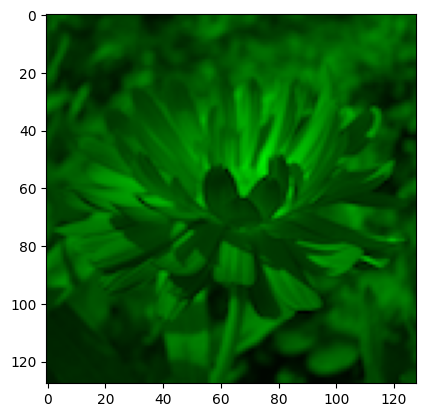

In [8]:
# Laag 2 (Laag 1 en 3 nul)
bloem1_copy = copy.deepcopy(bloem1)
bloem1_copy[:,:,0] = np.zeros_like(layer1) # zet laag 1 allemaal op nul
bloem1_copy[:,:,2] = np.zeros_like(layer3) # zet laag 3 allemaal op nul
plt.imshow(bloem1_copy)

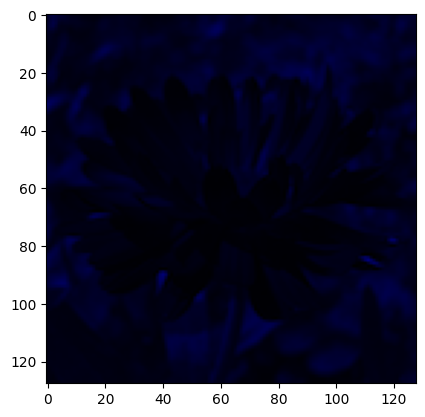

In [9]:
# Laag 3 (Laag 1 en 2 nul)
bloem1_copy = copy.deepcopy(bloem1)
bloem1_copy[:,:,0] = np.zeros_like(layer1) # zet laag 1 allemaal op nul
bloem1_copy[:,:,1] = np.zeros_like(layer2) # zet laag 2 allemaal op nul
plt.imshow(bloem1_copy)

Laag 2 geeft een groene afbeelding en laag 3 een blauwe. De hypothese klopt: de lagen zijn **R**ood, **G**roen, **B**lauw en (A)lpha.

### 2.2. Berekenen van de features

We willen onze afbeelding kwantificeren aan de hand van enkele variabelen die we moeten berekenen. In de les hebben we het voorbeeld met de som gezien. Laten we dus de som voor elke kleur berekenen en kijken hoe we die gegevens kunnen samenbrengen in een matrixachtige structuur (een ndarray in Python).

Nu gaan we kenmerken uit de afbeelding extraheren door kleursommen te berekenen. Dit is een eenvoudige aanpak voor 'feature engineering', waarbij we elke afbeelding reduceren tot drie numerieke waarden die de totale intensiteit van elk kleurkanaal vertegenwoordigen:

In [10]:
RedSum = layer1.sum()
GreenSum = layer2.sum()
BlueSum = layer3.sum()

RGB_sums = [[RedSum, GreenSum, BlueSum]]

Laten we de resultaten van onze kenmerkberekening bekijken:

In [11]:
RGB_sums

[[np.float32(8152.263), np.float32(5193.024), np.float32(1677.9609)]]

In [12]:
# Test: met np.append kunnen we rijen onder elkaar plakken (dit gebruiken we straks in de lus)
test = np.append(RGB_sums, RGB_sums, axis = 0)
test

array([[8152.263 , 5193.024 , 1677.9609],
       [8152.263 , 5193.024 , 1677.9609]], dtype=float32)

### 2.3. Maken van de datamatrix

In [13]:
training_files = sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.png'))
print(f"Aantal afbeeldingen: {len(training_files)}")
training_files[:5]

Aantal afbeeldingen: 39


['0003.png', '0006.png', '0016.png', '0021.png', '0027.png']

Nu gaan we alle afbeeldingen systematisch verwerken. Deze lus extraheert RGB-somkenmerken uit elke afbeelding:

In [14]:
RGB_Sum_results = np.empty((0, 3), float) # initialization of empty ndarray

for file in training_files:
    bloem = img.imread(os.path.join(DATA_DIR, file))

    RED_layer = bloem[:,:,0]
    GREEN_layer = bloem[:,:,1]
    BLUE_layer = bloem[:,:,2]

    RedSum = RED_layer.sum()
    GreenSum = GREEN_layer.sum()
    BlueSum = BLUE_layer.sum()

    RGB_sum = [[RedSum, GreenSum, BlueSum]]
    RGB_Sum_results = np.append(RGB_Sum_results, RGB_sum, axis = 0)

print(RGB_Sum_results.shape)
RGB_Sum_results[:5]

(39, 3)


array([[ 8152.26318359,  5193.02392578,  1677.9609375 ],
       [ 7731.9453125 ,  6704.78857422,  5322.921875  ],
       [11879.86328125,  6369.71777344,  6365.16894531],
       [ 8142.69433594,  5617.30224609,  2015.39233398],
       [ 8487.77636719,  4844.77685547,  1975.85900879]])

### 2.4. Target

- Bepaal de bloemsoort voor elk bestand; y van ons ML-model
- Maak een dataframe aan met de bestandsnamen en de features, zodat deze aan de labels kunnen worden gekoppeld

In [15]:
flower_metadata = pd.read_csv(LABEL_FILE, header = 0, sep = ";")
flower_metadata.head()

,Unnamed: 0,file,label,name
0,3,0003.png,2,calendula
1,6,0006.png,1,rose
2,16,0016.png,1,rose
3,21,0021.png,2,calendula
4,27,0027.png,2,calendula


Combineer de labels met onze RGB-kenmerkgegevens om de volledige dataset te creëren. We koppelen op bestandsnaam, zodat elke rij gegarandeerd het juiste label krijgt:

In [16]:
features = pd.DataFrame(RGB_Sum_results, columns = ['RedSum', 'GreenSum', 'BlueSum'])
features['file'] = training_files

df_full = pd.merge(features, flower_metadata[['file', 'name']], on = 'file')
print(f"Aantal rijen: {len(df_full)}")
df_full.head()

Aantal rijen: 39


,RedSum,GreenSum,BlueSum,file,name
0,8152.263184,5193.023926,1677.960938,0003.png,calendula
1,7731.945312,6704.788574,5322.921875,0006.png,rose
2,11879.863281,6369.717773,6365.168945,0016.png,rose
3,8142.694336,5617.302246,2015.392334,0021.png,calendula
4,8487.776367,4844.776855,1975.859009,0027.png,calendula


In [17]:
# Verdeling van de klassen en gemiddelde kleursom per soort
print(df_full['name'].value_counts(), end="\n\n")
df_full.groupby('name')[['RedSum', 'GreenSum', 'BlueSum']].mean()

name
rose         20
calendula    19
Name: count, dtype: int64



,RedSum,GreenSum,BlueSum
name,,,
calendula,7868.361971,5729.509252,2135.343628
rose,8179.089258,6443.049060,4452.000232


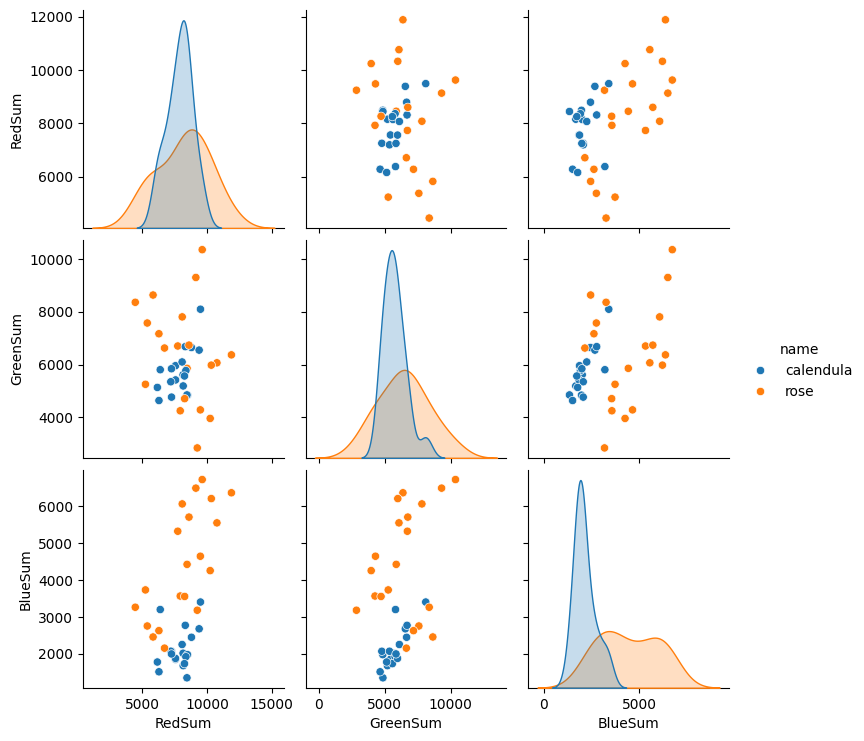

In [18]:
sns.pairplot(df_full[['RedSum', 'GreenSum', 'BlueSum', 'name']], hue = 'name')
plt.show()

De dataset is mooi gebalanceerd (20 rozen, 19 goudsbloemen). Vooral **BlueSum** lijkt de twee soorten goed te scheiden: rozen bevatten gemiddeld veel meer blauw dan de oranje/gele goudsbloemen (calendula).

## **Stap 3:** Splitsen in Training en Test set

In [19]:
X = df_full[['RedSum', 'GreenSum', 'BlueSum']]
y = df_full['name']

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)

print(f"Omvang trainingset: {x_train.shape[0]} | Omvang testset: {x_test.shape[0]}")
print("Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is")

Omvang trainingset: 27 | Omvang testset: 12
Note: stratify=y zorgt ervoor dat de verdeling van de doelvariabele in train en test hetzelfde is


## **Stap 4:** ML Pipeline

We trainen drie modellen en vergelijken ze:
1. **Random Forest** (baseline uit de vorige les): veel onafhankelijke bomen (bagging), waarvan de stemmen gecombineerd worden.
2. **Gradient Boosted Trees**: bomen worden *na elkaar* gebouwd; elke nieuwe boom corrigeert de fouten van de vorige (boosting).
3. **Support Vector Machine (SVM)**: zoekt de grens (hyperplane) met de grootste marge tussen de klassen. SVM is gevoelig voor de schaal van de features, dus we standaardiseren eerst met `StandardScaler` in een pipeline.

In [20]:
modellen = {
    'Random Forest': RandomForestClassifier(n_estimators = 100, random_state = 42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators = 100, learning_rate = 0.1, max_depth = 3, random_state = 42),
    'SVM': make_pipeline(StandardScaler(), SVC(kernel = 'rbf', probability = True, random_state = 42)),
}

for naam, model in modellen.items():
    model.fit(x_train, y_train)
    print(f"{naam} getraind")

Random Forest getraind
Gradient Boosting getraind
SVM getraind


### 4.1. Boosted Trees in detail

**Hoe werkt Gradient Boosting?**
1. Start met een eenvoudige voorspelling (de log-odds van de klassenverdeling).
2. Bereken de fouten (residuen / gradiënten) van de huidige voorspelling.
3. Train een kleine boom (`max_depth`) die deze fouten voorspelt.
4. Tel deze boom op bij het model, vermenigvuldigd met de `learning_rate`.
5. Herhaal `n_estimators` keer.

Belangrijke hyperparameters:
- `n_estimators`: aantal bomen. Te veel bomen → overfitting.
- `learning_rate`: hoe sterk elke boom meetelt. Kleiner = voorzichtiger leren, maar meer bomen nodig.
- `max_depth`: diepte van elke boom. Bij boosting meestal klein (1–3), het zijn 'zwakke leerders'.

**Feature importance**: welke kleur gebruiken de boommodellen het meest om te beslissen?

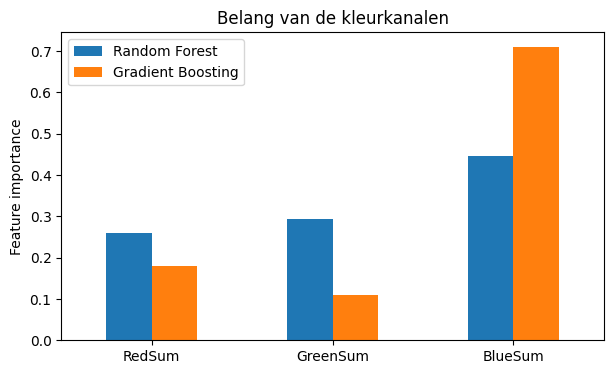

,Random Forest,Gradient Boosting
RedSum,0.260,0.18
GreenSum,0.293,0.11
BlueSum,0.447,0.71


In [21]:
importance = pd.DataFrame({
    'Random Forest': modellen['Random Forest'].feature_importances_,
    'Gradient Boosting': modellen['Gradient Boosting'].feature_importances_,
}, index = X.columns)

importance.plot(kind = 'bar', figsize = (7, 4), rot = 0)
plt.ylabel('Feature importance')
plt.title('Belang van de kleurkanalen')
plt.show()
importance.round(3)

## **Stap 5:** Evaluatie

### Op de trainingset

`predict_proba` geeft een kolom per klasse, in de volgorde van `model.classes_` (alfabetisch: calendula, rose). Kolom 1 is dus de kans op **rose**.

In [22]:
ML_model = modellen['Random Forest']
print(ML_model.classes_)

y_pred = ML_model.predict(x_train)
y_probs = ML_model.predict_proba(x_train)[:, 1]

prediction_check = pd.DataFrame({'True label': y_train,
                                 'Predicted label': y_pred,
                                 'Probability rose': y_probs})
prediction_check

['calendula' 'rose']


,True label,Predicted label,Probability rose
11,rose,rose,0.92
33,rose,rose,0.85
20,calendula,calendula,0.07
12,rose,rose,0.97
32,calendula,calendula,0.22
7,rose,rose,0.79
31,calendula,calendula,0.08
4,calendula,calendula,0.05
10,rose,rose,0.99
28,rose,rose,0.66


In [23]:
for naam, model in modellen.items():
    acc = metrics.accuracy_score(y_train, model.predict(x_train))
    print(f"{naam:<18} accuracy op trainingset: {acc:.3f}")

Random Forest      accuracy op trainingset: 1.000
Gradient Boosting  accuracy op trainingset: 1.000
SVM                accuracy op trainingset: 0.926


Random Forest en Gradient Boosting scoren perfect op de trainingset. Dat zegt weinig: bomen kunnen de trainingsdata gewoon 'van buiten leren' (overfitting). Daarom evalueren we op de testset, die het model nog nooit gezien heeft.

### Evaluatie op de testset

=============== Random Forest ===============
              precision    recall  f1-score   support

   calendula       1.00      1.00      1.00         6
        rose       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12

=============== Gradient Boosting ===============
              precision    recall  f1-score   support

   calendula       1.00      1.00      1.00         6
        rose       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12

=============== SVM ===============


              precision    recall  f1-score   support

   calendula       1.00      1.00      1.00         6
        rose       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



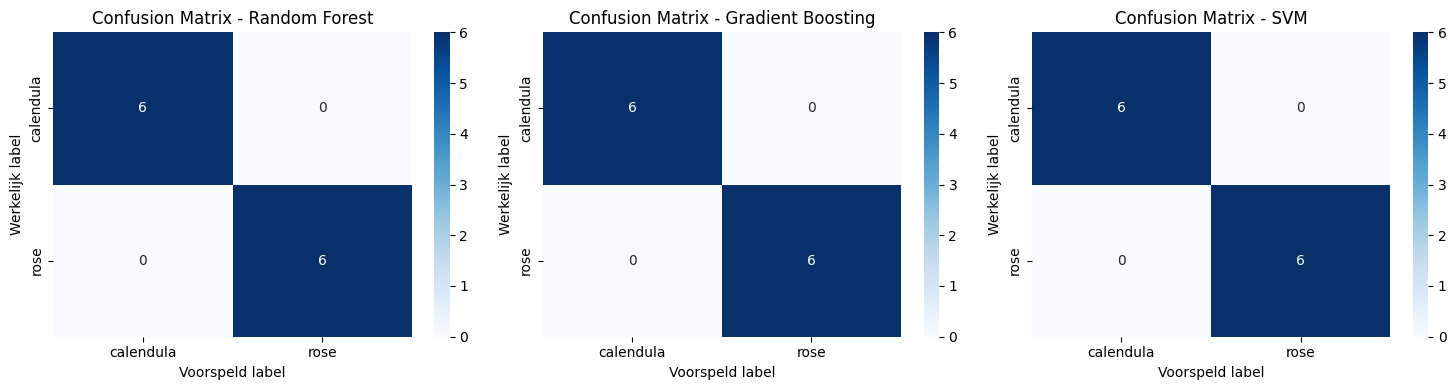

In [24]:
resultaten = []
fig, axes = plt.subplots(1, len(modellen), figsize = (5 * len(modellen), 4))

for ax, (naam, model) in zip(axes, modellen.items()):
    y_pred = model.predict(x_test)
    y_prob = model.predict_proba(x_test)[:, 1]  # kans op 'rose'

    print(f"{'='*15} {naam} {'='*15}")
    print(metrics.classification_report(y_test, y_pred, zero_division = 0))

    resultaten.append({
        'Model': naam,
        'Accuracy': metrics.accuracy_score(y_test, y_pred),
        'Precision (rose)': metrics.precision_score(y_test, y_pred, pos_label = 'rose', zero_division = 0),
        'Recall (rose)': metrics.recall_score(y_test, y_pred, pos_label = 'rose', zero_division = 0),
        'F1 (rose)': metrics.f1_score(y_test, y_pred, pos_label = 'rose', zero_division = 0),
        'ROC-AUC': metrics.roc_auc_score(y_test, y_prob),
    })

    cm = metrics.confusion_matrix(y_test, y_pred, labels = model.classes_)
    sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', ax = ax,
                xticklabels = model.classes_, yticklabels = model.classes_)
    ax.set_title(f'Confusion Matrix - {naam}')
    ax.set_xlabel('Voorspeld label')
    ax.set_ylabel('Werkelijk label')

plt.tight_layout()
plt.show()

### ROC Curve

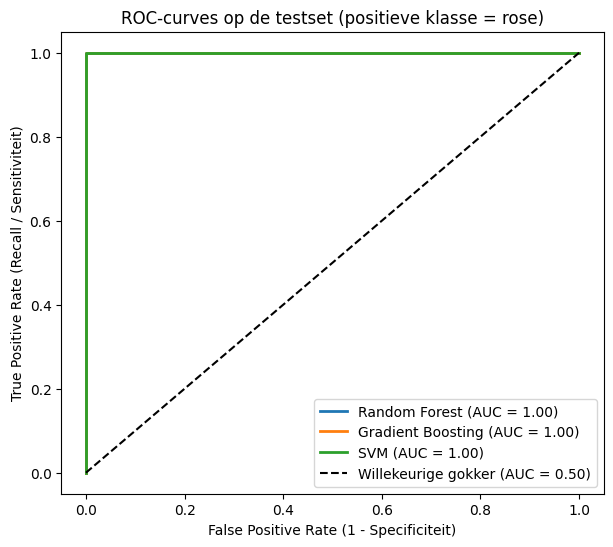

In [25]:
plt.figure(figsize = (7, 6))

for naam, model in modellen.items():
    y_prob = model.predict_proba(x_test)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, y_prob, pos_label = 'rose')
    auc_val = metrics.auc(fpr, tpr)
    plt.plot(fpr, tpr, lw = 2, label = f"{naam} (AUC = {auc_val:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label = 'Willekeurige gokker (AUC = 0.50)')
plt.xlabel('False Positive Rate (1 - Specificiteit)')
plt.ylabel('True Positive Rate (Recall / Sensitiviteit)')
plt.title('ROC-curves op de testset (positieve klasse = rose)')
plt.legend(loc = 'lower right')
plt.show()

### Cross-validatie

Onze testset bevat maar 12 bloemen; één fout meer of minder verandert de accuracy al met ~8%. Om een betrouwbaarder beeld te krijgen gebruiken we 5-fold (stratified) cross-validatie op de volledige dataset: elk model wordt 5 keer getraind en telkens op een ander deel getest.

In [26]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

for res in resultaten:
    scores = cross_val_score(modellen[res['Model']], X, y, cv = cv, scoring = 'accuracy')
    res['CV accuracy (gem.)'] = scores.mean()
    res['CV accuracy (std)'] = scores.std()

df_vergelijking = pd.DataFrame(resultaten).set_index('Model')
df_vergelijking.round(3)

,Accuracy,Precision (rose),Recall (rose),F1 (rose),ROC-AUC,CV accuracy (gem.),CV accuracy (std)
Model,,,,,,,
Random Forest,1.0,1.0,1.0,1.0,1.0,0.875,0.112
Gradient Boosting,1.0,1.0,1.0,1.0,1.0,0.800,0.187
SVM,1.0,1.0,1.0,1.0,1.0,0.950,0.061


## **Conclusie**

- De **RGB-kleursommen** zijn, ondanks hun eenvoud, sterke features: vooral de hoeveelheid blauw onderscheidt rozen van goudsbloemen.
- Op de (kleine) testset classificeren **alle drie de modellen alle 12 bloemen correct** (accuracy en ROC-AUC = 1.0). Op basis van de testset alleen kunnen we de modellen dus niet van elkaar onderscheiden.
- De **cross-validatie** geeft een eerlijker beeld: de **SVM** scoort het best (± 95%), gevolgd door **Random Forest** (± 88%) en **Gradient Boosting** (± 80%).
- Dat de boomgebaseerde modellen 100% halen op de trainingset maar lager scoren in cross-validatie wijst op **overfitting**: met slechts 39 afbeeldingen leren ze de trainingsdata te goed. Gradient Boosting is hier extra gevoelig voor omdat elke boom de resterende (soms toevallige) fouten probeert te corrigeren.
- De **feature importance** bevestigt de verkenning: Gradient Boosting baseert zich voor ± 70% op **BlueSum**, Random Forest verdeelt het belang meer over de drie kleuren.
- De SVM, met gestandaardiseerde features, legt een vloeiende grens met maximale marge en generaliseert daardoor beter op zo'n kleine dataset.
- **Verbeteringen**: meer afbeeldingen verzamelen en extra features toevoegen (bv. gemiddelde, standaardafwijking of histogrammen per kleurkanaal). Daarna kunnen ook de hyperparameters (bv. `n_estimators`, `learning_rate`, `max_depth`) getuned worden.